In [1]:
!pip install pandas-datareader
import pandas as pd
import pandas_datareader.data as web
import datetime

# Define the date range. Let's get data from 2000 to the present as an example.
start = datetime.datetime(1900, 1, 1)
end = datetime.date.today()

# Fetch the 49 Industry Portfolios Daily Data
print("Fetching 49 Industry Portfolios (Daily)...")
try:
    # The dataset name for 49 industries daily is '49_Industry_Portfolios_daily'
    ind49_daily = web.DataReader('49_Industry_Portfolios_daily', 'famafrench', start, end)
    ind49_df = ind49_daily[0] # Usually the first element contains the main dataset
    print("Successfully fetched Industry data.")
except Exception as e:
    print(f"Error fetching Industry data: {e}")

# Fetch the Fama-French 5 Factors Daily Data
print("Fetching Fama-French 5 Factors (Daily)...")
try:
    # The dataset name for 5 factors daily is 'F-F_Research_Data_5_Factors_2x3_daily'
    ff5_daily = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench', start, end)
    ff5_df = ff5_daily[0]
    print("Successfully fetched 5-Factor data.")
except Exception as e:
    print(f"Error fetching 5-Factor data: {e}")


Fetching 49 Industry Portfolios (Daily)...
Successfully fetched Industry data.
Fetching Fama-French 5 Factors (Daily)...
Successfully fetched 5-Factor data.


In [2]:
# Merge the datasets
print("Merging datasets...")
# Both dataframes should have the Date as index
merged_df = pd.merge(ind49_df, ff5_df, left_index=True, right_index=True, how='inner')

print(f"Merged data shape: {merged_df.shape}")
display(merged_df.head())


Merging datasets...
Merged data shape: (15897, 55)


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,...,Insur,RlEst,Fin,Other,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,,,,,,,,,,,,,,,,
1963-07-01,0.33,-0.45,-0.14,-0.20,0.11,-1.83,-1.40,-0.41,-0.62,-0.16,...,-1.35,-0.51,-0.20,0.14,-0.67,0.00,-0.33,-0.01,0.16,0.01
1963-07-02,0.86,0.65,-0.03,0.29,0.40,1.41,0.49,0.44,1.02,0.17,...,0.71,0.33,0.43,0.13,0.79,-0.26,0.26,-0.07,-0.20,0.01
1963-07-03,0.96,0.55,0.83,1.29,0.00,0.65,1.05,1.34,0.84,0.46,...,0.99,0.38,0.80,0.09,0.63,-0.17,-0.10,0.18,-0.34,0.01
1963-07-05,-0.01,0.09,0.32,0.35,0.59,0.43,1.34,-0.17,0.44,0.33,...,1.11,0.02,0.64,1.02,0.40,0.08,-0.27,0.09,-0.34,0.01
1963-07-08,-0.15,-0.28,0.26,-0.37,-0.41,-0.79,-0.97,-0.39,-0.61,-0.52,...,-0.79,-1.06,-0.02,-0.38,-0.63,0.04,-0.18,-0.29,0.14,0.01


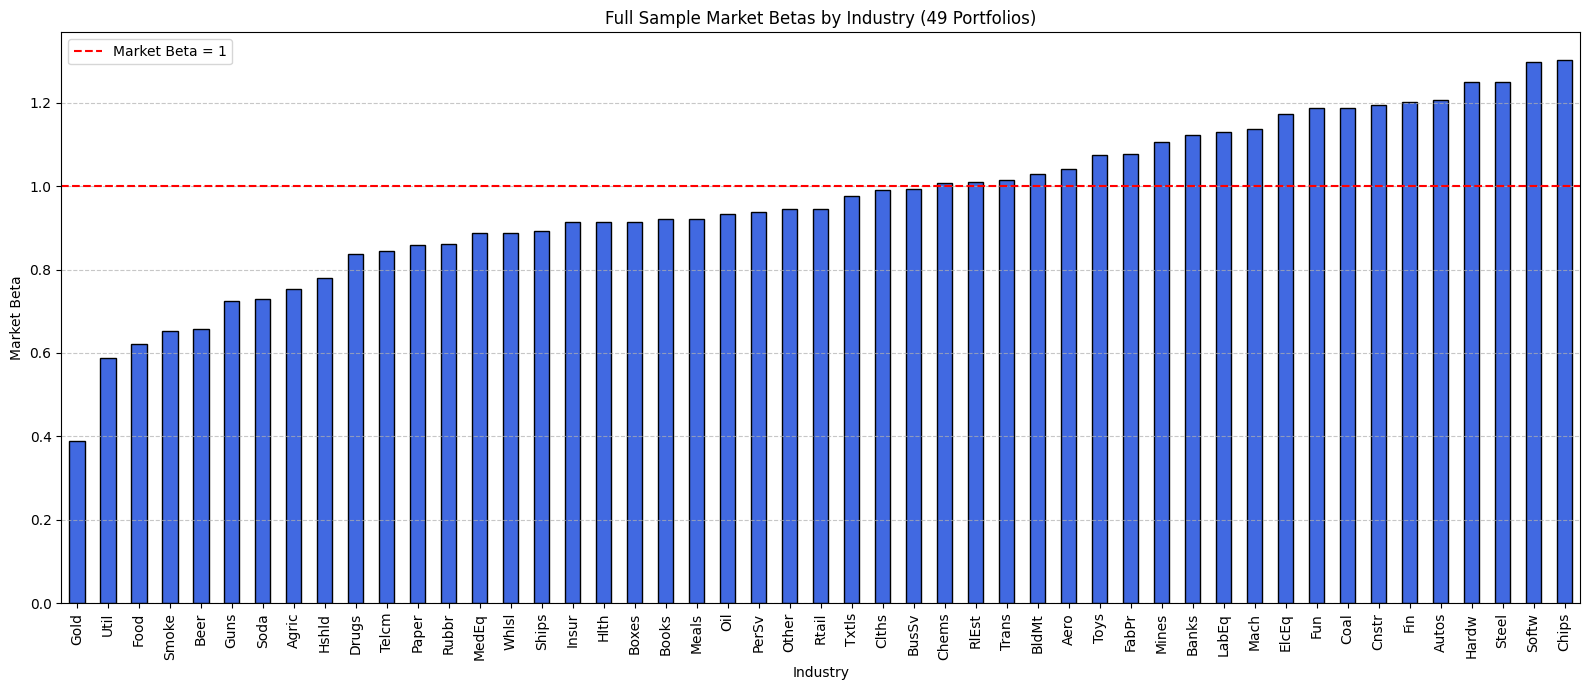

In [3]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np

# Identify the industry columns by excluding the factor columns
factor_cols = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']
industry_cols = [c for c in merged_df.columns if c not in factor_cols]

# Kenneth French's data sometimes uses -99.99 or -999 for missing values. Replace them with NaN.
clean_df = merged_df.replace([-99.99, -99.0, -999.0, -999], np.nan)

betas = {}

# Prepare the independent variable (Market factor) and add a constant for the intercept
X_market = sm.add_constant(clean_df['Mkt-RF'])

for ind in industry_cols:
    # Construct excess returns by subtracting the risk-free rate
    excess_return = clean_df[ind] - clean_df['RF']

    # Combine variables and drop missing values for the current industry's regression
    temp_df = pd.concat([excess_return.rename('Excess_Return'), X_market], axis=1).dropna()

    if not temp_df.empty:
        Y = temp_df['Excess_Return']
        X = temp_df[['const', 'Mkt-RF']]

        # Run OLS regression
        model = sm.OLS(Y, X).fit()

        # Extract and store the market beta (coefficient for 'Mkt-RF')
        betas[ind] = model.params['Mkt-RF']

# Convert to a pandas Series and sort for visualization
beta_series = pd.Series(betas).sort_values()

# Plot the betas
plt.figure(figsize=(16, 7))
beta_series.plot(kind='bar', color='royalblue', edgecolor='black')
plt.title('Full Sample Market Betas by Industry (49 Portfolios)')
plt.ylabel('Market Beta')
plt.xlabel('Industry')
plt.axhline(1.0, color='red', linestyle='--', label='Market Beta = 1') # Reference line for market average
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

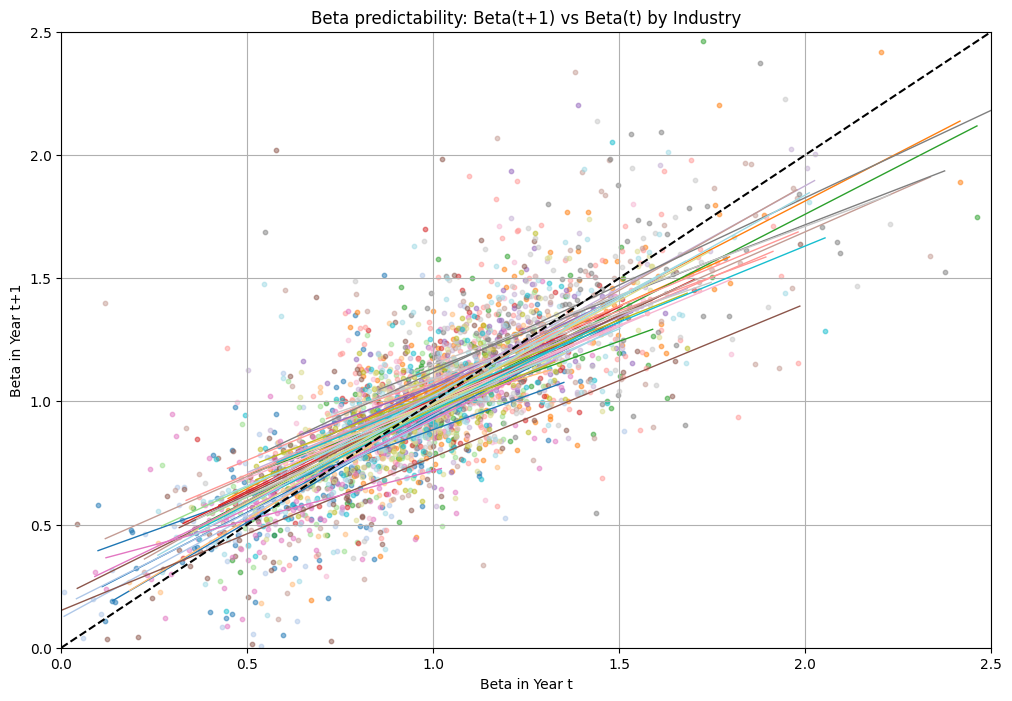

,Beta Predictability Slope
Industry,
Hshld,0.910760
Food,0.879453
Whlsl,0.867544
Mines,0.854309
RlEst,0.840103
Autos,0.832799
Beer,0.822076
Meals,0.819803
Fin,0.803683


In [4]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats

# Add 'Year' column to the clean_df
clean_df['Year'] = clean_df.index.year
years = sorted(clean_df['Year'].unique())

yearly_betas = {ind: {} for ind in industry_cols}

# Calculate yearly betas
for year in years:
    year_data = clean_df[clean_df['Year'] == year]
    if len(year_data) < 30: # Need enough observations to estimate beta
        continue

    X_market_year = sm.add_constant(year_data['Mkt-RF'])

    for ind in industry_cols:
        excess_return = year_data[ind] - year_data['RF']
        temp_df = pd.concat([excess_return.rename('Excess_Return'), X_market_year], axis=1).dropna()

        if not temp_df.empty and len(temp_df) > 30:
            Y = temp_df['Excess_Return']
            X = temp_df[['const', 'Mkt-RF']]
            model = sm.OLS(Y, X).fit()
            yearly_betas[ind][year] = model.params['Mkt-RF']

# Prepare data for plotting and regressions: Beta_t vs Beta_{t+1}
beta_pairs = {ind: {'current': [], 'next': []} for ind in industry_cols}
slopes = {}

plt.figure(figsize=(12, 8))
# Fixed deprecation warning by using plt.get_cmap instead of plt.cm.get_cmap
colors = plt.get_cmap('tab20', len(industry_cols))

for i, ind in enumerate(industry_cols):
    ind_years = sorted(yearly_betas[ind].keys())
    for j in range(len(ind_years) - 1):
        curr_year = ind_years[j]
        next_year = ind_years[j+1]

        if next_year == curr_year + 1: # ensure consecutive years
            beta_pairs[ind]['current'].append(yearly_betas[ind][curr_year])
            beta_pairs[ind]['next'].append(yearly_betas[ind][next_year])

    if len(beta_pairs[ind]['current']) > 5:
        x = np.array(beta_pairs[ind]['current'])
        y = np.array(beta_pairs[ind]['next'])

        # Scatter plot
        plt.scatter(x, y, color=colors(i), alpha=0.5, s=10)

        # Regression for the line and slope
        X_reg = sm.add_constant(x)
        model = sm.OLS(y, X_reg).fit()
        slopes[ind] = model.params[1]

        # Plot regression line
        x_vals = np.linspace(x.min(), x.max(), 100)
        y_vals = model.params[0] + model.params[1] * x_vals
        plt.plot(x_vals, y_vals, color=colors(i), linewidth=1)

plt.title('Beta predictability: Beta(t+1) vs Beta(t) by Industry')
plt.xlabel('Beta in Year t')
plt.ylabel('Beta in Year t+1')
# Adding a 45-degree line for reference
plt.plot([0, 2.5], [0, 2.5], 'k--', label='45 degree line')
plt.xlim([0, 2.5])
plt.ylim([0, 2.5])
plt.grid(True)
plt.show()

# Create and display the table of slopes
slopes_df = pd.DataFrame.from_dict(slopes, orient='index', columns=['Beta Predictability Slope'])
slopes_df.index.name = 'Industry'
slopes_df = slopes_df.sort_values(by='Beta Predictability Slope', ascending=False)
display(slopes_df)


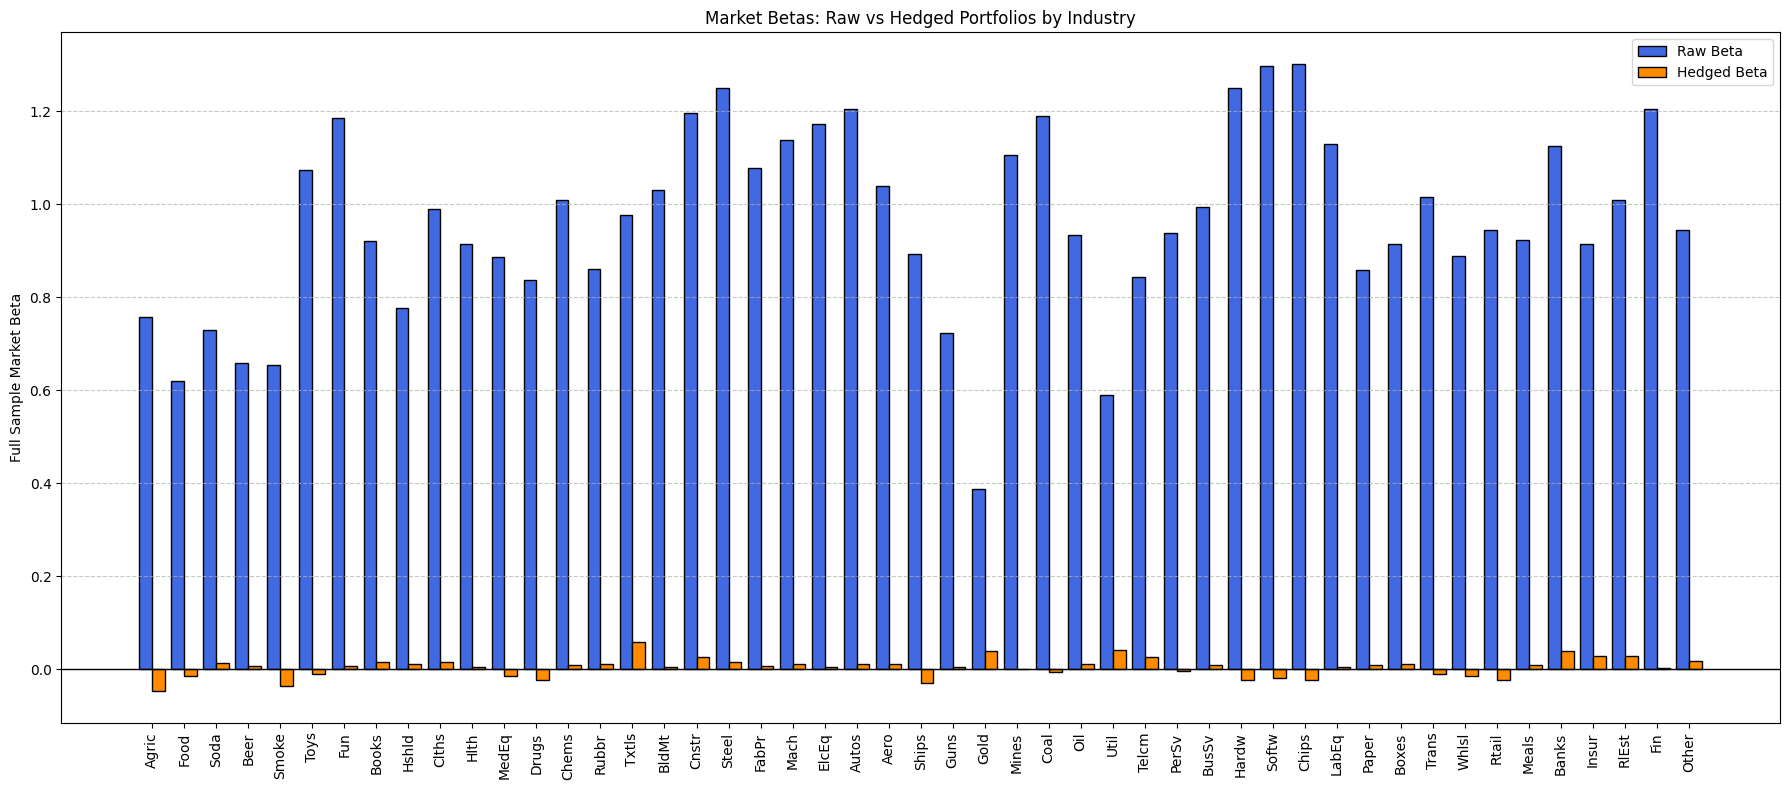

In [5]:
hedged_dfs = []

# Construct hedged portfolio returns year by year
for year in years:
    if year - 1 not in yearly_betas[industry_cols[0]]:
        continue # Skip if we don't have the previous year's beta to form the hedge

    year_data = clean_df[clean_df['Year'] == year]

    daily_hedged = pd.DataFrame(index=year_data.index)
    daily_hedged['Mkt-RF'] = year_data['Mkt-RF']

    for ind in industry_cols:
        if year - 1 in yearly_betas[ind]:
            beta_prev = yearly_betas[ind][year - 1]
            excess_return = year_data[ind] - year_data['RF']
            # Hedged return = Industry Excess Return - (Previous Year Beta * Market Excess Return)
            daily_hedged[ind] = excess_return - beta_prev * year_data['Mkt-RF']
        else:
            daily_hedged[ind] = np.nan

    hedged_dfs.append(daily_hedged)

# Combine all years into a single DataFrame
if hedged_dfs:
    hedged_df = pd.concat(hedged_dfs)

raw_betas = {}
hedged_betas = {}

# Calculate full sample betas for both Raw and Hedged returns (over the matched sample period)
X_market_full = sm.add_constant(hedged_df['Mkt-RF'])

for ind in industry_cols:
    # Hedged Beta
    temp_hedged = pd.concat([hedged_df[ind].rename('Hedged'), X_market_full], axis=1).dropna()
    if not temp_hedged.empty:
        model_hedged = sm.OLS(temp_hedged['Hedged'], temp_hedged[['const', 'Mkt-RF']]).fit()
        hedged_betas[ind] = model_hedged.params['Mkt-RF']

    # Raw Beta (for the exact same days we have hedged returns)
    raw_excess = clean_df.loc[hedged_df.index, ind] - clean_df.loc[hedged_df.index, 'RF']
    temp_raw = pd.concat([raw_excess.rename('Raw'), X_market_full], axis=1).dropna()
    if not temp_raw.empty:
        model_raw = sm.OLS(temp_raw['Raw'], temp_raw[['const', 'Mkt-RF']]).fit()
        raw_betas[ind] = model_raw.params['Mkt-RF']

# Plotting the comparison
ind_list = list(raw_betas.keys())
raw_b = [raw_betas[i] for i in ind_list]
hedged_b = [hedged_betas[i] for i in ind_list]

x = np.arange(len(ind_list))
width = 0.4

fig, ax = plt.subplots(figsize=(18, 8))
rects1 = ax.bar(x - width/2, raw_b, width, label='Raw Beta', color='royalblue', edgecolor='black')
rects2 = ax.bar(x + width/2, hedged_b, width, label='Hedged Beta', color='darkorange', edgecolor='black')

ax.set_ylabel('Full Sample Market Beta')
ax.set_title('Market Betas: Raw vs Hedged Portfolios by Industry')
ax.set_xticks(x)
ax.set_xticklabels(ind_list, rotation=90)
ax.legend()
plt.axhline(0, color='black', linewidth=1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

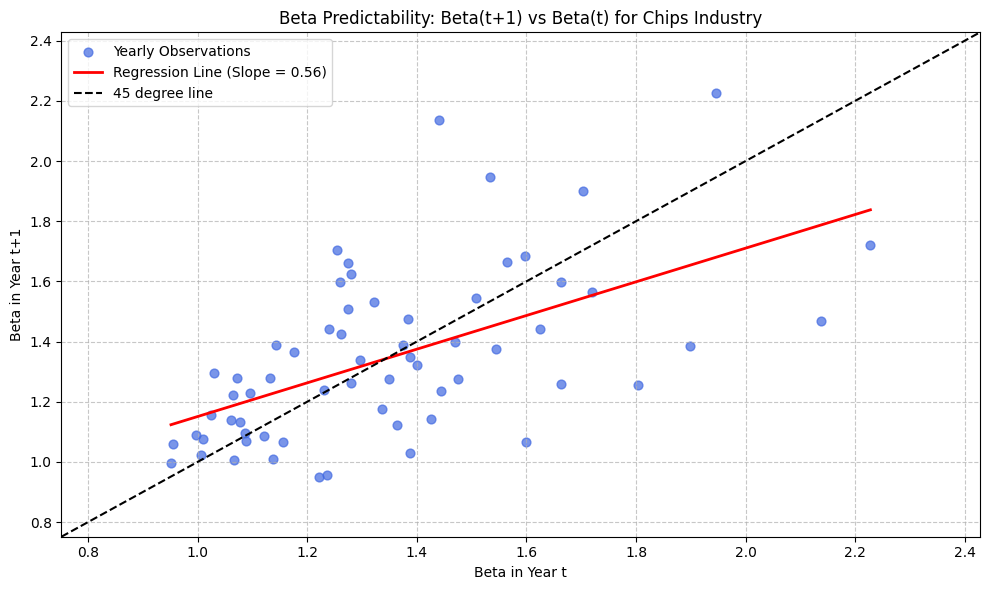

In [6]:
target_ind = 'Chips'

# Extract x (Beta t) and y (Beta t+1) for the target industry
x = np.array(beta_pairs[target_ind]['current'])
y = np.array(beta_pairs[target_ind]['next'])

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='royalblue', alpha=0.7, s=40, label='Yearly Observations')

# Calculate regression line
X_reg = sm.add_constant(x)
model = sm.OLS(y, X_reg).fit()

# Plot regression line
x_vals = np.linspace(x.min(), x.max(), 100)
y_vals = model.params[0] + model.params[1] * x_vals
plt.plot(x_vals, y_vals, color='red', linewidth=2, label=f'Regression Line (Slope = {model.params[1]:.2f})')

# Add 45-degree reference line
min_val = min(x.min(), y.min()) - 0.2
max_val = max(x.max(), y.max()) + 0.2
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='45 degree line')

plt.title(f'Beta Predictability: Beta(t+1) vs Beta(t) for {target_ind} Industry')
plt.xlabel('Beta in Year t')
plt.ylabel('Beta in Year t+1')
plt.xlim([min_val, max_val])
plt.ylim([min_val, max_val])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [7]:
yearly_alphas = {ind: {} for ind in industry_cols}

# Calculate yearly alphas (intercepts)
for year in years:
    year_data = clean_df[clean_df['Year'] == year]
    if len(year_data) < 30:
        continue

    X_market_year = sm.add_constant(year_data['Mkt-RF'])

    for ind in industry_cols:
        excess_return = year_data[ind] - year_data['RF']
        temp_df = pd.concat([excess_return.rename('Excess_Return'), X_market_year], axis=1).dropna()

        if not temp_df.empty and len(temp_df) > 30:
            Y = temp_df['Excess_Return']
            X = temp_df[['const', 'Mkt-RF']]
            model = sm.OLS(Y, X).fit()
            # Store the alpha (const parameter)
            yearly_alphas[ind][year] = model.params['const']

strategy_returns = []
strategy_mkt = []

# Construct strategy returns year by year
for year in years:
    if year - 1 not in yearly_alphas[industry_cols[0]]:
        continue # Skip if we don't have the previous year's alpha to form the weights

    year_data = clean_df[clean_df['Year'] == year]
    if year_data.empty:
        continue

    # Extract previous year alphas for all industries
    alphas_prev = {ind: yearly_alphas[ind].get(year - 1, np.nan) for ind in industry_cols}

    # Filter out missing values
    valid_alphas = {k: v for k, v in alphas_prev.items() if not np.isnan(v)}
    if not valid_alphas:
        continue

    # Weights proportional to the alpha. We normalize by the sum of absolute alphas
    # to keep gross leverage at 1 (sum of abs weights = 1)
    total_abs_alpha = sum(abs(v) for v in valid_alphas.values())
    if total_abs_alpha == 0:
        continue

    weights = {ind: alpha / total_abs_alpha for ind, alpha in valid_alphas.items()}

    # Calculate daily strategy returns for this year
    daily_strat_ret = pd.Series(0.0, index=year_data.index)
    for ind, w in weights.items():
        daily_strat_ret += w * (year_data[ind] - year_data['RF'])

    strategy_returns.append(daily_strat_ret)
    strategy_mkt.append(year_data['Mkt-RF'])

strat_ret_series = pd.concat(strategy_returns).rename('Strategy')
mkt_ret_series = pd.concat(strategy_mkt).rename('Mkt-RF')
print("Strategy constructed successfully.")

Strategy constructed successfully.


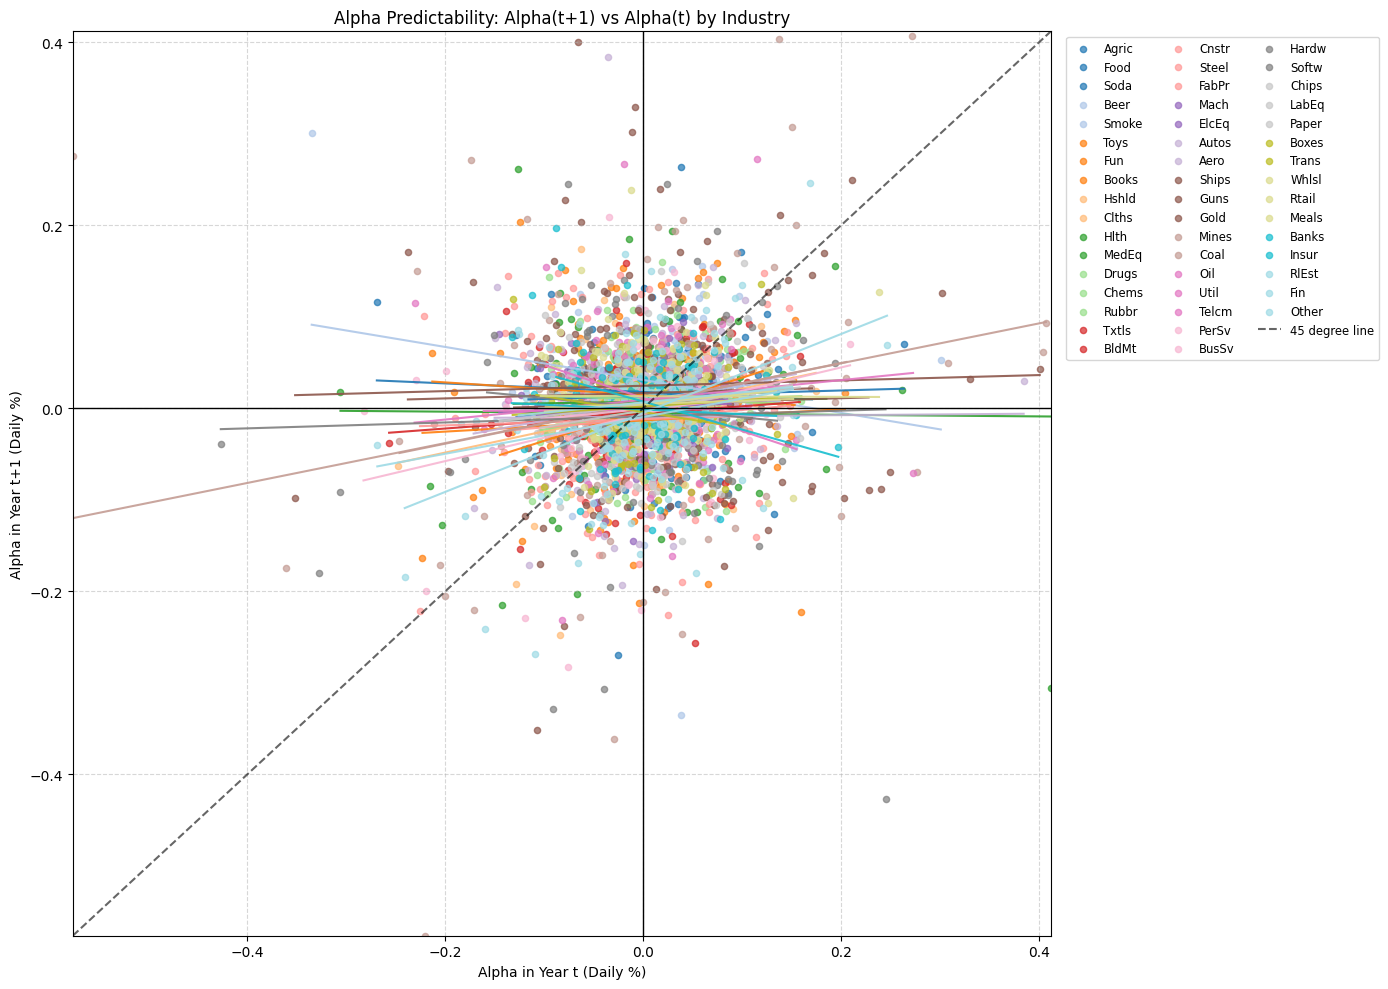

In [11]:
# Prepare data for Alpha_t vs Alpha_{t+1}
import statsmodels.api as sm

alpha_pairs = {ind: {'current': [], 'next': []} for ind in industry_cols}

plt.figure(figsize=(14, 10))
colors = plt.get_cmap('tab20', len(industry_cols))

all_x = []
all_y = []

for i, ind in enumerate(industry_cols):
    ind_years = sorted(yearly_alphas[ind].keys())
    for j in range(len(ind_years) - 1):
        curr_year = ind_years[j]
        next_year = ind_years[j+1]

        if next_year == curr_year + 1: # ensure consecutive years
            val_curr = yearly_alphas[ind][curr_year]
            val_next = yearly_alphas[ind][next_year]
            alpha_pairs[ind]['current'].append(val_curr)
            alpha_pairs[ind]['next'].append(val_next)
            all_x.append(val_curr)
            all_y.append(val_next)

    if len(alpha_pairs[ind]['current']) > 0:
        x = np.array(alpha_pairs[ind]['current'])
        y = np.array(alpha_pairs[ind]['next'])
        # Scatter plot for the industry
        plt.scatter(x, y, color=colors(i), alpha=0.7, s=20, label=ind)

        # Add regression slope line for the industry
        if len(x) > 1:
            X_reg = sm.add_constant(x)
            model = sm.OLS(y, X_reg).fit()
            if len(model.params) > 1:
                x_vals = np.linspace(x.min(), x.max(), 100)
                y_vals = model.params[0] + model.params[1] * x_vals
                plt.plot(x_vals, y_vals, color=colors(i), linewidth=1.5, alpha=0.9)

plt.title('Alpha Predictability: Alpha(t+1) vs Alpha(t) by Industry')
plt.xlabel('Alpha in Year t (Daily %)')
plt.ylabel('Alpha in Year t+1 (Daily %)')

# Add zero axes lines
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

# Adding a 45-degree line for reference
if all_x and all_y:
    min_val = min(min(all_x), min(all_y))
    max_val = max(max(all_x), max(all_y))
    plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='45 degree line', alpha=0.6)
    plt.xlim([min_val, max_val])
    plt.ylim([min_val, max_val])

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', ncol=3, fontsize='small')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Strategy Daily Alpha: 0.008612%
Strategy Alpha t-stat: 1.93
Strategy Market Beta: 0.0652
Leverage applied to Market to match Strategy Volatility: 0.5506


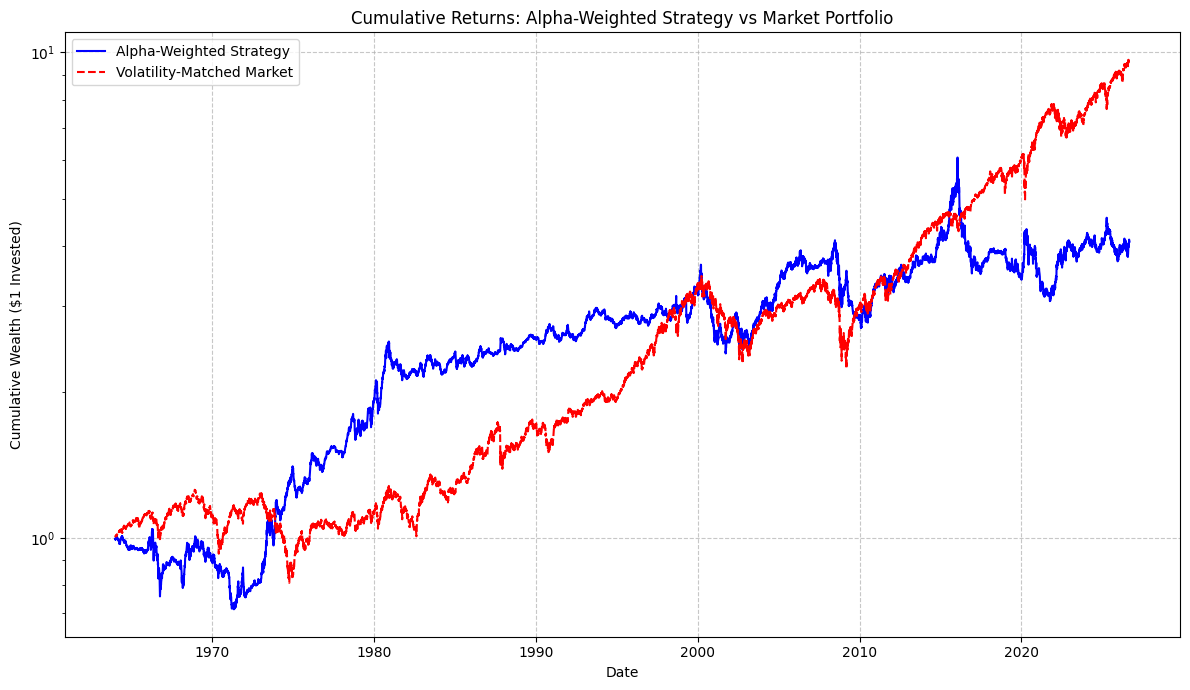

In [10]:
# Evaluate the strategy overall alpha
temp_strat = pd.concat([strat_ret_series, mkt_ret_series], axis=1).dropna()
if not temp_strat.empty:
    X_strat = sm.add_constant(temp_strat['Mkt-RF'])
    model_strat = sm.OLS(temp_strat['Strategy'], X_strat).fit()
    strat_alpha = model_strat.params['const']
    strat_beta = model_strat.params['Mkt-RF']
    strat_tval = model_strat.tvalues['const']

    print(f"Strategy Daily Alpha: {strat_alpha:.6f}%")
    print(f"Strategy Alpha t-stat: {strat_tval:.2f}")
    print(f"Strategy Market Beta: {strat_beta:.4f}")
else:
    print("Not enough data to calculate Strategy Alpha.")

# Calculate the leveraged market return
strat_vol = strat_ret_series.std()
mkt_vol = mkt_ret_series.std()
leverage = strat_vol / mkt_vol
print(f"Leverage applied to Market to match Strategy Volatility: {leverage:.4f}")

leveraged_mkt = mkt_ret_series * leverage

# Cumulative returns (Fama-French data is in percentages, so divide by 100)
cum_strat = (1 + strat_ret_series.fillna(0) / 100).cumprod()
cum_mkt = (1 + leveraged_mkt.fillna(0) / 100).cumprod()

plt.figure(figsize=(12, 7))

try:
    plot_index = cum_strat.index.to_timestamp()
except AttributeError:
    plot_index = cum_strat.index

plt.plot(plot_index, cum_strat.values, label='Alpha-Weighted Strategy', color='blue', linewidth=1.5)
plt.plot(plot_index, cum_mkt.values, label='Volatility-Matched Market', color='red', linestyle='--', linewidth=1.5)
plt.title('Cumulative Returns: Alpha-Weighted Strategy vs Market Portfolio')
plt.ylabel('Cumulative Wealth ($1 Invested)')
plt.xlabel('Date')
plt.yscale('log') # Log scale handles compounding visualization better
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()